# Heat_1D: effect of under-relaxation around the freezing point

Compares `pyAPES.soil.heat.Heat_1D` with and without the under-relaxation fix in `heatflow1D`
(`T_iter = 0.5 * (T_iter + T_iterold)` after iteration 5). The "without fix" version is built from the
current `heat.py` source by removing the fix block, so both versions share all other code.

In [1]:
import re
import sys
import types
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  # repo root, when run from debug_notebooks/

import pyAPES.soil.heat as heat_fixed

FIX_PATTERN = re.compile(
    r"[ \t]*# under-relax[^\n]*\n[ \t]*if iterNo > 5:\n[ \t]*T_iter = 0\.5 \* \(T_iter \+ T_iterold\)\n")


def load_unfixed_module():
    src = Path(heat_fixed.__file__).read_text()
    src, n = FIX_PATTERN.subn("", src)
    if n != 1:
        raise RuntimeError("Fix block not found in heat.py; update FIX_PATTERN.")
    mod = types.ModuleType("heat_unfixed")
    mod.__file__ = heat_fixed.__file__
    exec(compile(src, heat_fixed.__file__, "exec"), mod.__dict__)
    return mod


heat_unfixed = load_unfixed_module()

In [2]:
def make_column(heat_mod, T_ini, w_tot=0.85):
    dz = np.array([0.01] * 10 + [0.02] * 10 + [0.05] * 14 + [0.1] * 40)
    z = dz / 2 - np.cumsum(dz)
    N = len(dz)
    grid = {'z': z, 'dz': dz,
            'dzu': np.r_[dz[0] / 2, z[:-1] - z[1:]],
            'dzl': np.r_[z[:-1] - z[1:], dz[-1] / 2]}
    prof = {'porosity': np.full(N, 0.93),
            'solid_heat_capacity': np.full(N, np.nan),
            'solid_composition': {'organic': np.ones(N), 'sand': np.zeros(N),
                                  'silt': np.zeros(N), 'clay': np.zeros(N)},
            'freezing_curve': np.full(N, 0.5),
            'bedrock_thermal_conductivity': np.full(N, np.nan)}
    specs = {'solve': True,
             'initial_condition': {'temperature': T_ini},
             'lower_boundary': {'type': 'temperature', 'value': T_ini}}
    return heat_mod.Heat_1D(grid, prof, specs, np.full(N, w_tot)), N, z


def run_case(heat_mod, T_ini, amplitude, ndays=10, dt=1800.0, w_tot=0.85):
    """Sinusoidal daily ground heat flux (upward positive, as in Heat_1D) [W m-2]."""
    h, N, z = make_column(heat_mod, T_ini, w_tot)
    wtot = np.full(N, w_tot)
    nsteps = int(ndays * 86400 / dt)
    steps_per_day = int(86400 / dt)
    out = {'t': np.arange(nsteps) * dt / 86400.0,
           'flux': np.zeros(nsteps), 'closure': np.zeros(nsteps),
           'T0': np.zeros(nsteps), 'T5': np.zeros(nsteps), 'T20': np.zeros(nsteps),
           'z': z}
    ix5, ix20 = np.argmin(abs(z + 0.05)), np.argmin(abs(z + 0.20))
    for k in range(nsteps):
        F = amplitude * np.sin(2 * np.pi * k / steps_per_day)
        f = h.run(dt, {'ground_heat_flux': F, 'date': k}, wtot)
        out['flux'][k] = F
        out['closure'][k] = f['energy_closure']
        out['T0'][k] = h.T[0]
        out['T5'][k] = h.T[ix5]
        out['T20'][k] = h.T[ix20]
    return out

In [3]:
cases = [
    ('Cooling/freezing: T_ini=2 degC, amp 60 W m-2', dict(T_ini=2.0, amplitude=60.0)),
    ('Thaw near 0 degC: T_ini=-0.3 degC, amp 80 W m-2', dict(T_ini=-0.3, amplitude=-80.0)),
]

results = []
for title, kw in cases:
    res_old = run_case(heat_unfixed, **kw)
    res_new = run_case(heat_fixed, **kw)
    results.append((title, res_old, res_new))
    for lbl, res in (('without fix', res_old), ('with fix', res_new)):
        print(f"{title} | {lbl:12s} max|closure| = {abs(res['closure']).max():8.3f} W m-2, "
              f"steps >1 W m-2: {(abs(res['closure']) > 1).sum()}")

Cooling/freezing: T_ini=2 degC, amp 60 W m-2 | without fix  max|closure| =   60.000 W m-2, steps >1 W m-2: 40
Cooling/freezing: T_ini=2 degC, amp 60 W m-2 | with fix     max|closure| =    0.017 W m-2, steps >1 W m-2: 0
Thaw near 0 degC: T_ini=-0.3 degC, amp 80 W m-2 | without fix  max|closure| =   80.000 W m-2, steps >1 W m-2: 387
Thaw near 0 degC: T_ini=-0.3 degC, amp 80 W m-2 | with fix     max|closure| =    0.017 W m-2, steps >1 W m-2: 0


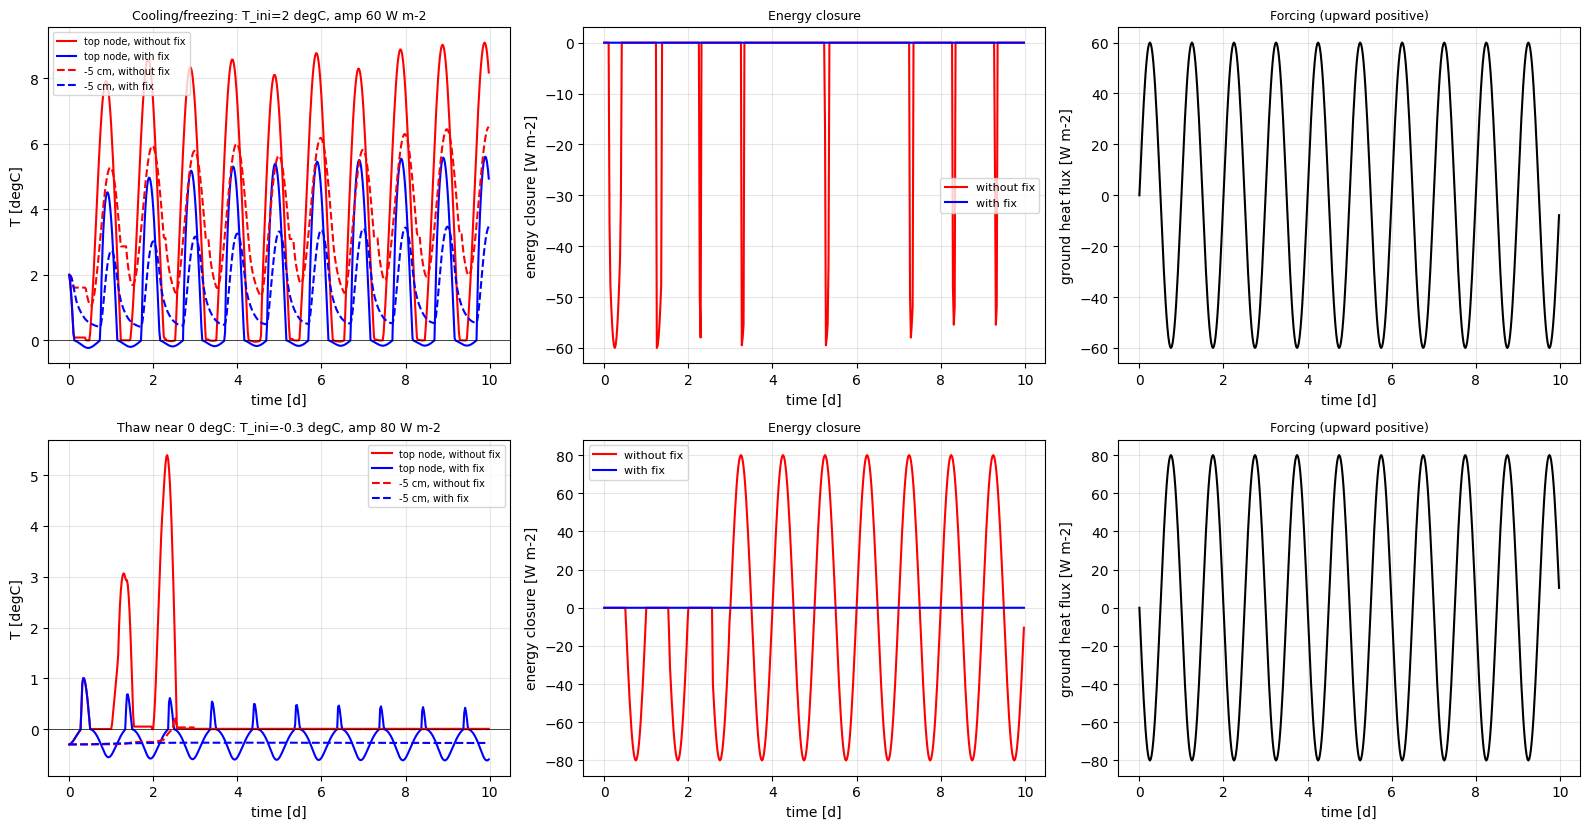

In [4]:
fig, axes = plt.subplots(len(results), 3, figsize=(16, 4.2 * len(results)), squeeze=False)

for r, (title, res_old, res_new) in enumerate(results):
    ax = axes[r, 0]
    ax.plot(res_old['t'], res_old['T0'], 'r-', label='top node, without fix')
    ax.plot(res_new['t'], res_new['T0'], 'b-', label='top node, with fix')
    ax.plot(res_old['t'], res_old['T5'], 'r--', label='-5 cm, without fix')
    ax.plot(res_new['t'], res_new['T5'], 'b--', label='-5 cm, with fix')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylabel('T [degC]')
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7)

    ax = axes[r, 1]
    ax.plot(res_old['t'], res_old['closure'], 'r-', label='without fix')
    ax.plot(res_new['t'], res_new['closure'], 'b-', label='with fix')
    ax.set_ylabel('energy closure [W m-2]')
    ax.set_title('Energy closure', fontsize=9)
    ax.legend(fontsize=8)

    ax = axes[r, 2]
    ax.plot(res_new['t'], res_new['flux'], 'k-')
    ax.set_ylabel('ground heat flux [W m-2]')
    ax.set_title('Forcing (upward positive)', fontsize=9)

    for c in range(3):
        axes[r, c].set_xlabel('time [d]')
        axes[r, c].grid(alpha=0.3)

fig.tight_layout()
plt.show()